In [1]:
import nltk
import string
from nltk.corpus import movie_reviews, stopwords
from nltk.tokenize import word_tokenize

# Download required resources
nltk.download('movie_reviews')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Load raw text from movie reviews corpus
raw_text = ""
for fileid in movie_reviews.fileids():
    raw_text += movie_reviews.raw(fileid)

# 1. Lowercasing
raw_text = raw_text.lower()

# 2. Tokenization
tokens = word_tokenize(raw_text)

# 3. Removing punctuation & stopwords
stop_words = set(stopwords.words('english'))
punctuations = set(string.punctuation)

clean_tokens = [
    word for word in tokens
    if word.isalpha() and word not in stop_words
]

# Vocabulary
vocab = set(clean_tokens)

# Print results
print("Vocabulary size:", len(vocab))
print("First 20 tokens:", clean_tokens[:20])

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Vocabulary size: 37964
First 20 tokens: ['plot', 'two', 'teen', 'couples', 'go', 'church', 'party', 'drink', 'drive', 'get', 'accident', 'one', 'guys', 'dies', 'girlfriend', 'continues', 'see', 'life', 'nightmares', 'deal']


In [4]:
%pip install gensim

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.6/26.6 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 15.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.2
    Uninstalling scipy-1.16.2:
      Successfully uninstalled scipy-1.16.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
tsfresh 0.21.1 requires scipy>=1.14.0;

In [2]:
import time
from gensim.models import Word2Vec

# Prepare sentences (list of lists)
sentences = []
for fileid in movie_reviews.fileids():
    words = word_tokenize(movie_reviews.raw(fileid).lower())
    words = [w for w in words if w.isalpha() and w not in stop_words]
    sentences.append(words)

embedding_dim = 100
window_size = 5
min_count = 3

# ---- CBOW ----
start = time.time()
cbow_model = Word2Vec(sentences, vector_size=embedding_dim,
                      window=window_size, min_count=min_count,
                      sg=0, workers=4)
cbow_time = time.time() - start

# ---- Skip-Gram ----
start = time.time()
skipgram_model = Word2Vec(sentences, vector_size=embedding_dim,
                          window=window_size, min_count=min_count,
                          sg=1, workers=4)
skipgram_time = time.time() - start

print("=== CBOW Model ===")
print("Vocabulary size:", len(cbow_model.wv))
print("Embedding dimension:", cbow_model.vector_size)
print("Training time: {:.2f} sec".format(cbow_time))

print("\n=== Skip-Gram Model ===")
print("Vocabulary size:", len(skipgram_model.wv))
print("Embedding dimension:", skipgram_model.vector_size)
print("Training time: {:.2f} sec".format(skipgram_time))

=== CBOW Model ===
Vocabulary size: 19368
Embedding dimension: 100
Training time: 11.47 sec

=== Skip-Gram Model ===
Vocabulary size: 19368
Embedding dimension: 100
Training time: 24.11 sec


In [3]:
# Top 10 similar words
print("Top 10 similar to 'king':", cbow_model.wv.most_similar("king", topn=10))

# Analogy: king - man + woman = ?
print("Analogy king - man + woman:", cbow_model.wv.most_similar(positive=["king", "woman"], negative=["man"], topn=1))

# Analogy: paris - france + italy = ?
print("Analogy paris - france + italy:", cbow_model.wv.most_similar(positive=["paris", "italy"], negative=["france"], topn=1))

Top 10 similar to 'king': [('ian', 0.9981759786605835), ('l', 0.9973214268684387), ('anthony', 0.9970788955688477), ('chris', 0.9970508813858032), ('thomas', 0.9967992305755615), ('captain', 0.9966825246810913), ('psychologist', 0.9966434240341187), ('jason', 0.9964504241943359), ('ray', 0.996316134929657), ('j', 0.9961791634559631)]
Analogy king - man + woman: [('h', 0.982026219367981)]
Analogy paris - france + italy: [('hot', 0.995995283126831)]


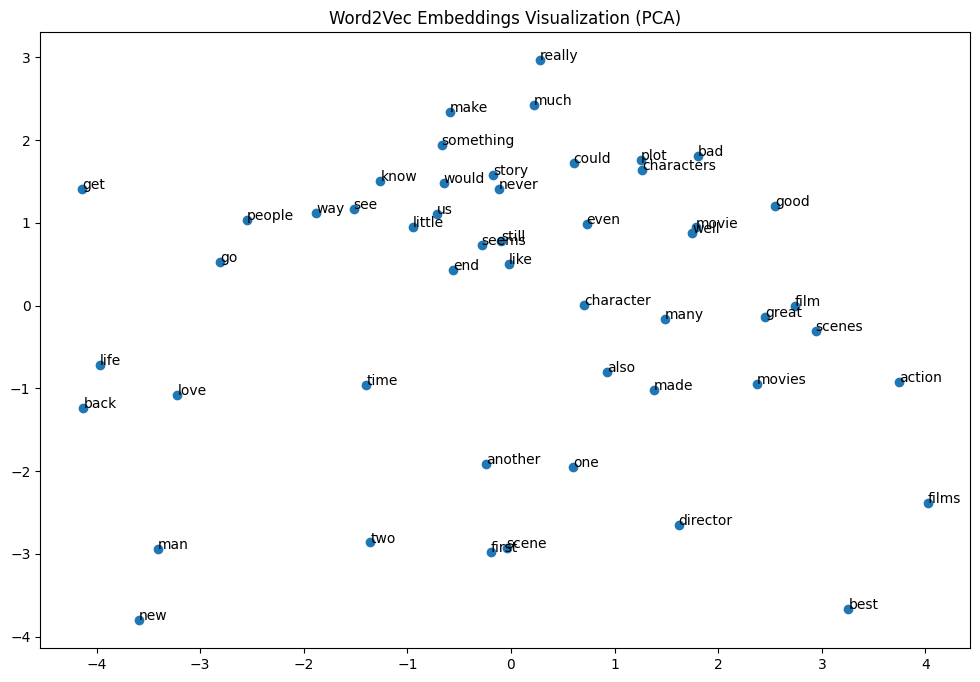

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Pick 50 words from vocabulary
words = list(cbow_model.wv.index_to_key)[:50]

# Extract embeddings
X = cbow_model.wv[words]

# Reduce to 2D using PCA
pca = PCA(n_components=2)
result = pca.fit_transform(X)

# Plot
plt.figure(figsize=(12,8))
plt.scatter(result[:, 0], result[:, 1])

for i, word in enumerate(words):
    plt.annotate(word, xy=(result[i, 0], result[i, 1]))

plt.title("Word2Vec Embeddings Visualization (PCA)")
plt.show()

In [5]:
import gensim.downloader as api

# Alternative: load smaller pretrained embeddings via gensim
pretrained = api.load("glove-wiki-gigaword-100")

# Compare similarity
print("Trained model similarity (king vs queen):", cbow_model.wv.similarity("king", "queen"))
print("Pretrained model similarity (king vs queen):", pretrained.similarity("king", "queen"))

print("Pretrained most similar to 'education':", pretrained.most_similar("education", topn=5))

[==================================================] 100.0% 128.1/128.1MB downloaded
Trained model similarity (king vs queen): 0.9923293
Pretrained model similarity (king vs queen): 0.7507691
Pretrained most similar to 'education': [('educational', 0.8206784129142761), ('schools', 0.7696099281311035), ('teaching', 0.7583372592926025), ('curriculum', 0.7522473931312561), ('programs', 0.7507966160774231)]
